Load the dataset

In [1]:
# Step 1: Upload the file
from google.colab import files
uploaded = files.upload()

# Step 2: Check if the file is uploaded
import os
print(os.listdir())  # This will list all files in the current directory

# Step 3: Read the CSV file (adjust the filename if necessary)
import pandas as pd
df = pd.read_csv('garments_worker_productivity.csv')  # Make sure the filename matches
print(df.head())  # Display the first few rows of the DataFrame

Saving garments_worker_productivity.csv to garments_worker_productivity (3).csv
['.config', 'garments_worker_productivity (3).csv', 'garments_worker_productivity (2).csv', 'garments_worker_productivity (1).csv', 'garments_worker_productivity.csv', 'drive', 'sample_data']
         date department       day  team  targeted_productivity    smv  \
0  01-01-2015     sewing  Thursday     8                   0.80  26.16   
1  01-01-2015  finishing  Thursday     1                   0.75   3.94   
2  01-01-2015     sewing  Thursday    11                   0.80  11.41   
3  01-01-2015     sewing  Thursday    12                   0.80  11.41   
4  01-01-2015     sewing  Thursday     6                   0.80  25.90   

      wip  over_time  incentive  idle_time  idle_men  no_of_style_change  \
0  1108.0       7080         98        0.0         0                   0   
1     NaN        960          0        0.0         0                   0   
2   968.0       3660         50        0.0         0   

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [3]:
df.shape
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1197 entries, 0 to 1196
Data columns (total 14 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   date                   1197 non-null   object 
 1   department             1197 non-null   object 
 2   day                    1197 non-null   object 
 3   team                   1197 non-null   int64  
 4   targeted_productivity  1197 non-null   float64
 5   smv                    1197 non-null   float64
 6   wip                    691 non-null    float64
 7   over_time              1197 non-null   int64  
 8   incentive              1197 non-null   int64  
 9   idle_time              1197 non-null   float64
 10  idle_men               1197 non-null   int64  
 11  no_of_style_change     1197 non-null   int64  
 12  no_of_workers          1197 non-null   float64
 13  actual_productivity    1197 non-null   float64
dtypes: float64(6), int64(5), object(3)
memory usage: 131.1+ 

Inspecting the dataset

In [4]:
# check dataset shape
print("Dataset shape:", df.shape)

# check column types
df.info()

# check missing values
df.isnull().sum()

Dataset shape: (1197, 14)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1197 entries, 0 to 1196
Data columns (total 14 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   date                   1197 non-null   object 
 1   department             1197 non-null   object 
 2   day                    1197 non-null   object 
 3   team                   1197 non-null   int64  
 4   targeted_productivity  1197 non-null   float64
 5   smv                    1197 non-null   float64
 6   wip                    691 non-null    float64
 7   over_time              1197 non-null   int64  
 8   incentive              1197 non-null   int64  
 9   idle_time              1197 non-null   float64
 10  idle_men               1197 non-null   int64  
 11  no_of_style_change     1197 non-null   int64  
 12  no_of_workers          1197 non-null   float64
 13  actual_productivity    1197 non-null   float64
dtypes: float64(6), int64(5), objec

,0
date,0
department,0
day,0
team,0
targeted_productivity,0
smv,0
wip,506
over_time,0
incentive,0
idle_time,0


Cleaning dataset

In [5]:
# -----------------------------
# DATA CLEANING
# -----------------------------

# 1 Fix department text issues
df['department'] = df['department'].astype(str).str.strip().str.lower()
df['department'] = df['department'].replace({'sweing': 'sewing'})

# 2 Convert date column safely (handles mixed formats like 1/13/2015)
df['date'] = pd.to_datetime(df['date'], errors='coerce', format='mixed')

# Remove rows where date could not be converted
df = df.dropna(subset=['date'])

# 3 Remove duplicate rows
df = df.drop_duplicates()

# 4 Ensure numeric columns are numeric
numeric_cols = [
    'targeted_productivity',
    'actual_productivity',
    'smv',
    'wip',
    'over_time',
    'incentive',
    'idle_time',
    'idle_men',
    'no_of_style_change',
    'no_of_workers'
]

for col in numeric_cols:
    df[col] = pd.to_numeric(df[col], errors='coerce')

# 5 Fill missing numeric values using median
df[numeric_cols] = df[numeric_cols].fillna(df[numeric_cols].median())

# 6 Sort dataset by team and date for time-based analysis
df = df.sort_values(['team', 'date'])

# Reset index
df = df.reset_index(drop=True)

print("Cleaning completed successfully")
print("Dataset shape:", df.shape)
df.head()

Cleaning completed successfully
Dataset shape: (1197, 14)


,date,department,day,team,targeted_productivity,smv,wip,over_time,incentive,idle_time,idle_men,no_of_style_change,no_of_workers,actual_productivity
0,2015-01-01,finishing,Thursday,1,0.75,3.94,1039.0,960,0,0.0,0,0,8.0,0.886500
1,2015-01-01,sewing,Thursday,1,0.75,28.08,681.0,6900,45,0.0,0,0,57.5,0.750428
2,2015-01-03,finishing,Saturday,1,0.80,3.94,1039.0,960,0,0.0,0,0,8.0,0.902917
3,2015-01-03,sewing,Saturday,1,0.80,28.08,772.0,6300,50,0.0,0,0,56.5,0.800725
4,2015-01-04,finishing,Sunday,1,0.80,3.94,1039.0,960,0,0.0,0,0,8.0,0.915229


Creating the normalization function

In [6]:
def normalize(series):

    min_val = series.min()
    max_val = series.max()

    if max_val - min_val == 0:
        return 0

    return (series - min_val) / (max_val - min_val)

Creating the KPIs (feature engineering)

In [7]:
# 1 planned to done ratio
df['planned_to_done_ratio'] = df['actual_productivity'] / df['targeted_productivity']

# 2 absenteeism proxy
df['scheduled_minutes'] = df['smv'] * df['no_of_workers']
df['absenteeism_rate'] = df['idle_time'] / df['scheduled_minutes']

# 3 output quality proxy
df['normalized_idle'] = normalize(df['idle_time'])
df['output_quality_rate'] = 1 - df['normalized_idle']

# 4 utilization rate
df['regular_time'] = 480 * df['no_of_workers']
df['available_time'] = df['regular_time'] + df['over_time']
df['productive_time'] = df['available_time'] - df['idle_time']
df['employee_utilization_rate'] = df['productive_time'] / df['available_time']

Behavioral Variables

In [8]:
# active work hours

df['active_work_time_hours'] = (df['productive_time'] / 60) / df['no_of_workers']

# task switching frequency
df['task_switching_frequency'] = normalize(df['no_of_style_change'])

# engagement score
df['norm_productivity'] = normalize(df['actual_productivity'])
df['norm_incentive'] = normalize(df['incentive'])

df['engagement_score'] = (
    0.5 * df['norm_productivity']
    + 0.3 * (1 - df['normalized_idle'])
    + 0.2 * df['norm_incentive']
)

Psychological Variables

In [9]:
df['norm_overtime'] = normalize(df['over_time'])
df['norm_style_change'] = normalize(df['no_of_style_change'])

# burnout score
df['burnout_score'] = (
    0.5 * df['norm_overtime']
    + 0.3 * df['normalized_idle']
    + 0.2 * df['norm_style_change']
)

# job satisfaction
df['job_satisfaction_score'] = (
    0.4 * df['norm_productivity']
    + 0.3 * df['norm_incentive']
    + 0.2 * (1 - df['normalized_idle'])
    + 0.1 * (1 - df['norm_style_change'])
)

The productivity trend

In [10]:
# -----------------------------
# Productivity trend calculation
# -----------------------------

df['rolling_avg_30'] = (
    df.groupby('team')['actual_productivity']
    .transform(lambda x: x.rolling(window=30, min_periods=5).mean())
)

# calculate trend
df['productivity_trend_last_30_days'] = (
    df['actual_productivity'] - df['rolling_avg_30']
)

# fix NaN values (happen at beginning of each team history)
df['productivity_trend_last_30_days'] = df['productivity_trend_last_30_days'].fillna(0)
df['rolling_avg_30'] = df['rolling_avg_30'].fillna(df['actual_productivity'])

Target Variable

In [11]:
df['productivity_decline_risk'] = (
    df['productivity_trend_last_30_days'] < -0.05
).astype(int)

Clipping the KPI Values

In [12]:
# -----------------------------
# Fix unrealistic KPI values
# -----------------------------

df['planned_to_done_ratio'] = df['planned_to_done_ratio'].clip(0, 2)

df['employee_utilization_rate'] = df['employee_utilization_rate'].clip(0, 1)

df['output_quality_rate'] = df['output_quality_rate'].clip(0, 1)

df['absenteeism_rate'] = df['absenteeism_rate'].clip(0, 1)

print("KPI values corrected")

KPI values corrected


Creating the final dataset

In [13]:
features = [
'planned_to_done_ratio',
'absenteeism_rate',
'output_quality_rate',
'employee_utilization_rate',
'engagement_score',
'active_work_time_hours',
'task_switching_frequency',
'burnout_score',
'job_satisfaction_score',
'productivity_trend_last_30_days',
'productivity_decline_risk'
]

final_df = df[features]

final_df.head()

,planned_to_done_ratio,absenteeism_rate,output_quality_rate,employee_utilization_rate,engagement_score,active_work_time_hours,task_switching_frequency,burnout_score,job_satisfaction_score,productivity_trend_last_30_days,productivity_decline_risk
0,1.182000,0.0,1.0,1.0,0.668090,10.000000,0.0,0.018519,0.594472,0.000000,0
1,1.000570,0.0,1.0,1.0,0.593863,10.000000,0.0,0.133102,0.536841,0.000000,0
2,1.128646,0.0,1.0,1.0,0.677347,10.000000,0.0,0.018519,0.601878,0.000000,0
3,1.000907,0.0,1.0,1.0,0.622502,9.858407,0.0,0.121528,0.559946,0.000000,0
4,1.144036,0.0,1.0,1.0,0.684290,10.000000,0.0,0.018519,0.607432,0.064069,0


Description of the distribution of variables

In [14]:
df.describe()

,date,team,targeted_productivity,smv,wip,over_time,incentive,idle_time,idle_men,no_of_style_change,...,norm_productivity,norm_incentive,engagement_score,norm_overtime,norm_style_change,burnout_score,job_satisfaction_score,rolling_avg_30,productivity_trend_last_30_days,productivity_decline_risk
count,1197,1197.000000,1197.000000,1197.000000,1197.000000,1197.000000,1197.000000,1197.000000,1197.000000,1197.000000,...,1197.000000,1197.000000,1197.000000,1197.000000,1197.000000,1197.000000,1197.000000,1197.000000,1197.000000,1197.000000
mean,2015-02-04 10:56:50.526315776,6.426901,0.729632,15.062172,1126.437761,4567.460317,38.210526,0.730159,0.369256,0.150376,...,0.565431,0.010614,0.584108,0.176214,0.075188,0.103875,0.521351,0.744044,-0.008953,0.284879
min,2015-01-01 00:00:00,1.000000,0.070000,2.900000,7.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.074213,0.000000,0.000000,0.000000,0.159370,0.436326,-0.606873,0.000000
25%,2015-01-18 00:00:00,3.000000,0.700000,3.940000,970.000000,1440.000000,0.000000,0.000000,0.000000,0.000000,...,0.469817,0.000000,0.536417,0.055556,0.000000,0.027778,0.467317,0.686270,-0.075480,0.000000
50%,2015-02-03 00:00:00,6.000000,0.750000,15.260000,1039.000000,3960.000000,0.000000,0.000000,0.000000,0.000000,...,0.608558,0.000000,0.604279,0.152778,0.000000,0.083333,0.537903,0.749632,0.012406,0.000000
75%,2015-02-23 00:00:00,9.000000,0.800000,24.260000,1083.000000,6960.000000,50.000000,0.000000,0.000000,0.000000,...,0.695303,0.013889,0.651163,0.268519,0.000000,0.162500,0.583069,0.800226,0.088710,1.000000
max,2015-03-11 00:00:00,12.000000,0.800000,54.560000,23122.000000,25920.000000,3600.000000,300.000000,45.000000,2.000000,...,1.000000,1.000000,0.842434,1.000000,1.000000,0.500000,0.873947,0.991389,0.380141,1.000000
std,NaN,3.463963,0.097891,10.943219,1397.653191,3348.823563,160.182643,12.709757,3.268987,0.427848,...,0.196776,0.044495,0.101291,0.129198,0.213924,0.080833,0.088790,0.079705,0.160379,0.451545


Dataset with the engineered features

In [15]:
# -----------------------------------------
# FINAL DATASET (ORIGINAL + ENGINEERED FEATURES)
# -----------------------------------------

print("Full dataset including engineered features\n")

# show first rows of full dataset
display(df.head())

# show dataset shape
print("\nDataset shape:", df.shape)

# show all column names
print("\nColumns in dataset:")
print(df.columns)

# summary statistics for all numeric columns
print("\nSummary statistics:")
display(df.describe())

Full dataset including engineered features



,date,department,day,team,targeted_productivity,smv,wip,over_time,incentive,idle_time,...,norm_productivity,norm_incentive,engagement_score,norm_overtime,norm_style_change,burnout_score,job_satisfaction_score,rolling_avg_30,productivity_trend_last_30_days,productivity_decline_risk
0,2015-01-01,finishing,Thursday,1,0.75,3.94,1039.0,960,0,0.0,...,0.736180,0.000000,0.668090,0.037037,0.0,0.018519,0.594472,0.886500,0.000000,0
1,2015-01-01,sewing,Thursday,1,0.75,28.08,681.0,6900,45,0.0,...,0.582727,0.012500,0.593863,0.266204,0.0,0.133102,0.536841,0.750428,0.000000,0
2,2015-01-03,finishing,Saturday,1,0.80,3.94,1039.0,960,0,0.0,...,0.754694,0.000000,0.677347,0.037037,0.0,0.018519,0.601878,0.902917,0.000000,0
3,2015-01-03,sewing,Saturday,1,0.80,28.08,772.0,6300,50,0.0,...,0.639449,0.013889,0.622502,0.243056,0.0,0.121528,0.559946,0.800725,0.000000,0
4,2015-01-04,finishing,Sunday,1,0.80,3.94,1039.0,960,0,0.0,...,0.768579,0.000000,0.684290,0.037037,0.0,0.018519,0.607432,0.851160,0.064069,0



Dataset shape: (1197, 35)

Columns in dataset:
Index(['date', 'department', 'day', 'team', 'targeted_productivity', 'smv',
       'wip', 'over_time', 'incentive', 'idle_time', 'idle_men',
       'no_of_style_change', 'no_of_workers', 'actual_productivity',
       'planned_to_done_ratio', 'scheduled_minutes', 'absenteeism_rate',
       'normalized_idle', 'output_quality_rate', 'regular_time',
       'available_time', 'productive_time', 'employee_utilization_rate',
       'active_work_time_hours', 'task_switching_frequency',
       'norm_productivity', 'norm_incentive', 'engagement_score',
       'norm_overtime', 'norm_style_change', 'burnout_score',
       'job_satisfaction_score', 'rolling_avg_30',
       'productivity_trend_last_30_days', 'productivity_decline_risk'],
      dtype='object')

Summary statistics:


,date,team,targeted_productivity,smv,wip,over_time,incentive,idle_time,idle_men,no_of_style_change,...,norm_productivity,norm_incentive,engagement_score,norm_overtime,norm_style_change,burnout_score,job_satisfaction_score,rolling_avg_30,productivity_trend_last_30_days,productivity_decline_risk
count,1197,1197.000000,1197.000000,1197.000000,1197.000000,1197.000000,1197.000000,1197.000000,1197.000000,1197.000000,...,1197.000000,1197.000000,1197.000000,1197.000000,1197.000000,1197.000000,1197.000000,1197.000000,1197.000000,1197.000000
mean,2015-02-04 10:56:50.526315776,6.426901,0.729632,15.062172,1126.437761,4567.460317,38.210526,0.730159,0.369256,0.150376,...,0.565431,0.010614,0.584108,0.176214,0.075188,0.103875,0.521351,0.744044,-0.008953,0.284879
min,2015-01-01 00:00:00,1.000000,0.070000,2.900000,7.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.074213,0.000000,0.000000,0.000000,0.159370,0.436326,-0.606873,0.000000
25%,2015-01-18 00:00:00,3.000000,0.700000,3.940000,970.000000,1440.000000,0.000000,0.000000,0.000000,0.000000,...,0.469817,0.000000,0.536417,0.055556,0.000000,0.027778,0.467317,0.686270,-0.075480,0.000000
50%,2015-02-03 00:00:00,6.000000,0.750000,15.260000,1039.000000,3960.000000,0.000000,0.000000,0.000000,0.000000,...,0.608558,0.000000,0.604279,0.152778,0.000000,0.083333,0.537903,0.749632,0.012406,0.000000
75%,2015-02-23 00:00:00,9.000000,0.800000,24.260000,1083.000000,6960.000000,50.000000,0.000000,0.000000,0.000000,...,0.695303,0.013889,0.651163,0.268519,0.000000,0.162500,0.583069,0.800226,0.088710,1.000000
max,2015-03-11 00:00:00,12.000000,0.800000,54.560000,23122.000000,25920.000000,3600.000000,300.000000,45.000000,2.000000,...,1.000000,1.000000,0.842434,1.000000,1.000000,0.500000,0.873947,0.991389,0.380141,1.000000
std,NaN,3.463963,0.097891,10.943219,1397.653191,3348.823563,160.182643,12.709757,3.268987,0.427848,...,0.196776,0.044495,0.101291,0.129198,0.213924,0.080833,0.088790,0.079705,0.160379,0.451545


Preparing the dataset for modeling

In [16]:
# -----------------------------------
# CHUNK A — PREPARE DATA FOR MACHINE LEARNING
# -----------------------------------

features = [
    'planned_to_done_ratio',
    'absenteeism_rate',
    'output_quality_rate',
    'employee_utilization_rate',
    'engagement_score',
    'active_work_time_hours',
    'task_switching_frequency',
    'burnout_score',
    'job_satisfaction_score'
]

X = df[features]
y = df['productivity_decline_risk']

print("Feature matrix shape:", X.shape)
print("\nTarget distribution:")
print(y.value_counts())

Feature matrix shape: (1197, 9)

Target distribution:
productivity_decline_risk
0    856
1    341
Name: count, dtype: int64


Train/Test Split

In [17]:
# -----------------------------------
# SPLIT DATASET
# -----------------------------------

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape)
print("Testing samples:", X_test.shape)

Training samples: (957, 9)
Testing samples: (240, 9)


Model Comparison with Cross-Validation

In [18]:
# -----------------------------------
# MODEL COMPARISON WITH CROSS VALIDATION
# -----------------------------------

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.model_selection import cross_val_score

models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Random Forest": RandomForestClassifier(n_estimators=200, random_state=42),
    "Gradient Boosting": GradientBoostingClassifier()
}

print("Cross Validation Results:\n")

for name, model in models.items():

    scores = cross_val_score(model, X, y, cv=5)

    print(name)
    print("Mean Accuracy:", round(scores.mean(), 3))
    print("Scores:", scores)
    print("----------------------------")

Cross Validation Results:

Logistic Regression
Mean Accuracy: 0.895
Scores: [0.85       0.87916667 0.91213389 0.90794979 0.92468619]
----------------------------
Random Forest
Mean Accuracy: 0.902
Scores: [0.875      0.89583333 0.87866109 0.93723849 0.92468619]
----------------------------
Gradient Boosting
Mean Accuracy: 0.909
Scores: [0.87916667 0.9        0.88702929 0.94560669 0.93305439]
----------------------------


Training the best model (Random Forest)

In [19]:
# -----------------------------------
# TRAIN FINAL MODEL
# -----------------------------------

from sklearn.ensemble import RandomForestClassifier

model = RandomForestClassifier(
    n_estimators=300,
    random_state=42
)

model.fit(X_train, y_train)

RandomForestClassifier(n_estimators=300, random_state=42)

Evaluate Model

In [20]:
# -----------------------------------
# CHUNK E — MODEL EVALUATION
# -----------------------------------

from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, roc_auc_score

y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]

print("Model Accuracy:", accuracy_score(y_test, y_pred))

print("\nClassification Report:\n")
print(classification_report(y_test, y_pred))

print("\nConfusion Matrix:\n")
print(confusion_matrix(y_test, y_pred))

print("\nROC AUC Score:", roc_auc_score(y_test, y_prob))

Model Accuracy: 0.925

Classification Report:

              precision    recall  f1-score   support

           0       0.96      0.93      0.95       172
           1       0.84      0.91      0.87        68

    accuracy                           0.93       240
   macro avg       0.90      0.92      0.91       240
weighted avg       0.93      0.93      0.93       240


Confusion Matrix:

[[160  12]
 [  6  62]]

ROC AUC Score: 0.963919288645691


Feature Importance

In [21]:
# -----------------------------------
# CHUNK F — FEATURE IMPORTANCE
# -----------------------------------

import pandas as pd

importance = pd.Series(
    model.feature_importances_,
    index=features
).sort_values(ascending=False)

print("Feature Importance:\n")
print(importance)

Feature Importance:

engagement_score             0.404502
job_satisfaction_score       0.270365
planned_to_done_ratio        0.210721
burnout_score                0.052375
active_work_time_hours       0.038322
task_switching_frequency     0.015039
absenteeism_rate             0.003302
employee_utilization_rate    0.002773
output_quality_rate          0.002601
dtype: float64


Visualization

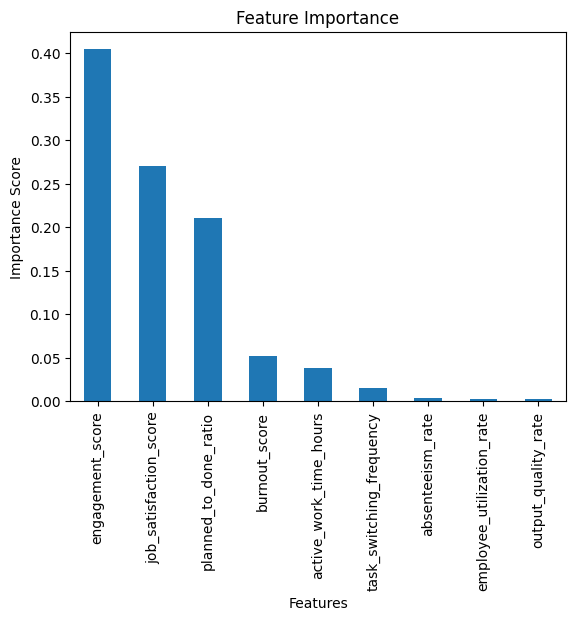

In [22]:
import matplotlib.pyplot as plt

importance.plot(kind='bar')

plt.title("Feature Importance")
plt.ylabel("Importance Score")
plt.xlabel("Features")

plt.show()